<a href="https://colab.research.google.com/github/FOYEJ1027/-Neural-Networks-Lab/blob/main/(CNN%20Shape%20Recognition)%20and%20Question%202%20(GRU%20vs%20RNN%20Sunspots%20Forecasting).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CNN Shape Recognition and
GRU vs RNN Sunspots Forecasting


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import time
import statsmodels.api as sm

torch.manual_seed(42)
np.random.seed(42)

# Q1: CNN Shape Recognition

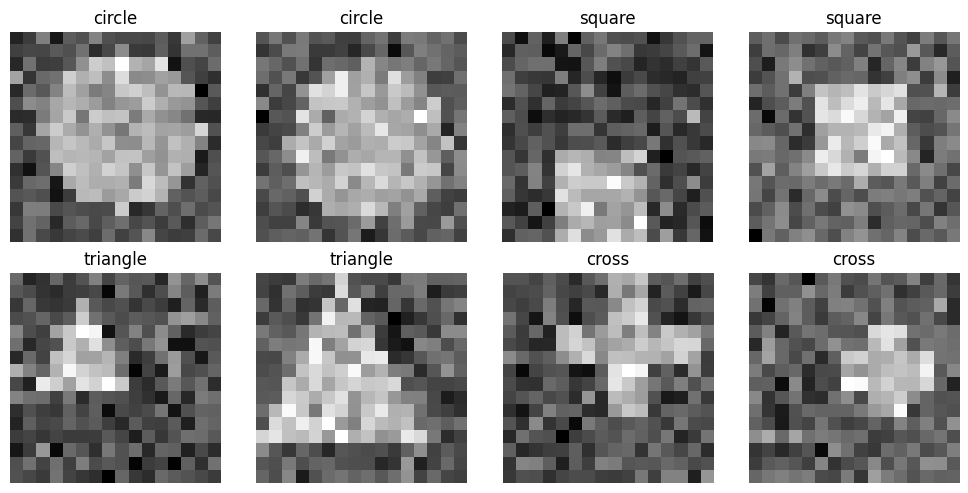

In [19]:
def make_shapes(n_per_class=400, size=16, seed=42):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:size, 0:size]
    X, y = [], []
    for label in range(4):
        for _ in range(n_per_class):
            r = rng.integers(3, 7)
            cx, cy = rng.integers(r, size - r, size=2)
            dx, dy = xx - cx, yy - cy
            if label == 0:   img = dx**2 + dy**2 <= r**2
            elif label == 1: img = (abs(dx) <= r) & (abs(dy) <= r)
            elif label == 2: img = (abs(dy) <= r) & (abs(dx) <= (dy + r) / 2)
            else:            img = ((abs(dx) <= 1) & (abs(dy) <= r)) | ((abs(dy) <= 1) & (abs(dx) <= r))
            X.append(img + 0.3 * rng.standard_normal((size, size))); y.append(label)
    return torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(1), torch.tensor(y)

X, y = make_shapes()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
train_ds, test_ds = TensorDataset(X_tr, y_tr), TensorDataset(X_te, y_te)
classes = ['circle', 'square', 'triangle', 'cross']

gen = torch.Generator().manual_seed(42)
tr_size = int(len(train_ds) * 0.8)
val_size = len(train_ds) - tr_size
tr_ds, val_ds = random_split(train_ds, [tr_size, val_size], generator=gen)

train_loader = DataLoader(tr_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
sorted_idx = sorted(range(len(tr_ds)), key=lambda idx: tr_ds[idx][1])
counts = {0: 0, 1: 0, 2: 0, 3: 0}
selected = []
for idx in sorted_idx:
    img, lbl = tr_ds[idx]
    lbl = int(lbl)
    if counts[lbl] < 2:
        selected.append((img, lbl))
        counts[lbl] += 1
    if len(selected) == 8:
        break

for i, (img, lbl) in enumerate(selected):
    ax = axes[i // 4, i % 4]
    ax.imshow(img.squeeze().numpy(), cmap='gray')
    ax.set_title(classes[lbl])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [20]:
class ShapeNet(nn.Module):
    def __init__(self):
        super(ShapeNet, self).__init__()
        self.layer2 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.layer3 = nn.MaxPool2d(2)
        self.layer4 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.layer5 = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.layer6 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.layer8 = nn.Sequential(
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5)
        )
        self.layer9 = nn.Linear(128, 4)

    def forward(self, x):
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = self.layer6(x)
        x = x.view(x.size(0), -1)
        x = self.layer8(x)
        x = self.layer9(x)
        return x

model_q1 = ShapeNet()
print(model_q1)

input_tensor = torch.zeros(1, 1, 16, 16)
model_q1.eval()
with torch.no_grad():
    x = input_tensor
    print("Layer 1 Input:", x.shape)
    x = model_q1.layer2(x)
    print("Layer 2 Conv + BN + ReLU:", x.shape)
    x = model_q1.layer3(x)
    print("Layer 3 MaxPool:", x.shape)
    x = model_q1.layer4(x)
    print("Layer 4 Conv + BN + ReLU:", x.shape)
    x = model_q1.layer5(x)
    print("Layer 5 MaxPool + Dropout:", x.shape)
    x = model_q1.layer6(x)
    print("Layer 6 Conv + BN + ReLU:", x.shape)
    x = x.view(x.size(0), -1)
    print("Layer 7 Flatten:", x.shape)
    x = model_q1.layer8(x)
    print("Layer 8 Linear + ReLU + Dropout:", x.shape)
    x = model_q1.layer9(x)
    print("Layer 9 Linear:", x.shape)

ShapeNet(
  (layer2): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layer3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (layer4): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layer5): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): Dropout(p=0.25, inplace=False)
  )
  (layer6): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (layer8): Sequential(
    (0): Linear(in_features=1024, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, i

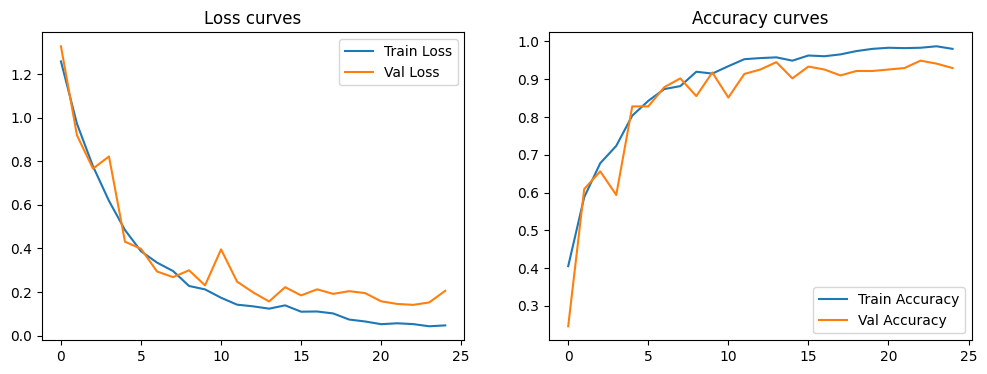

In [21]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_q1.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_loss = float('inf')
best_weights = None

for epoch in range(25):
    model_q1.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_b, y_b in train_loader:
        optimizer.zero_grad()
        outputs = model_q1(X_b)
        loss = criterion(outputs, y_b)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_b.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == y_b).sum().item()
        total += y_b.size(0)

    epoch_train_loss = running_loss / len(tr_ds)
    epoch_train_acc = correct / total

    model_q1.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for X_b, y_b in val_loader:
            outputs = model_q1(X_b)
            loss = criterion(outputs, y_b)
            val_loss += loss.item() * X_b.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == y_b).sum().item()
            val_total += y_b.size(0)

    epoch_val_loss = val_loss / len(val_ds)
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    scheduler.step(epoch_val_loss)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_weights = model_q1.state_dict().copy()

if best_weights is not None:
    model_q1.load_state_dict(best_weights)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_title('Loss curves')
ax1.legend()

ax2.plot(train_accs, label='Train Accuracy')
ax2.plot(val_accs, label='Val Accuracy')
ax2.set_title('Accuracy curves')
ax2.legend()
plt.show()

              precision    recall  f1-score   support

      circle       0.91      0.84      0.87        80
      square       0.87      1.00      0.93        80
    triangle       1.00      0.99      0.99        80
       cross       0.96      0.90      0.93        80

    accuracy                           0.93       320
   macro avg       0.93      0.93      0.93       320
weighted avg       0.93      0.93      0.93       320



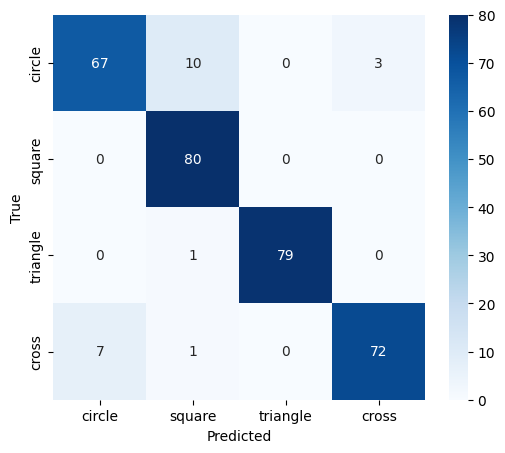

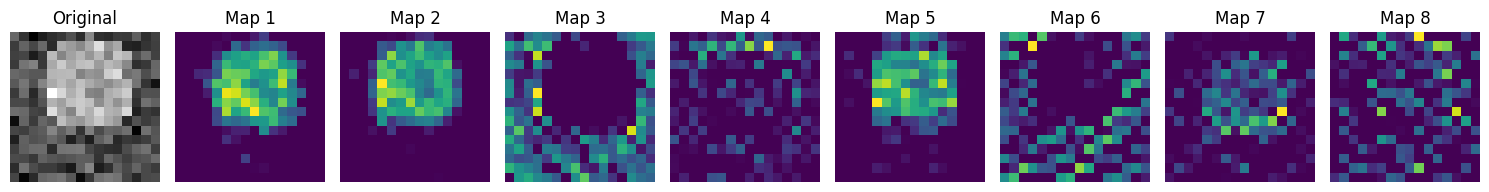

In [12]:
model_q1.eval()
test_preds = []
test_targets = []
with torch.no_grad():
    for X_b, y_b in test_loader:
        outputs = model_q1(X_b)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.numpy())
        test_targets.extend(y_b.numpy())

print(classification_report(test_targets, test_preds, target_names=classes))

cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

test_img, test_label = test_ds[0]
original_img = test_img.squeeze().numpy()

with torch.no_grad():
    fmaps = model_q1.layer2(test_img.unsqueeze(0))
fmaps = fmaps.squeeze(0).numpy()

fig, axes = plt.subplots(1, 9, figsize=(15, 3))
axes[0].imshow(original_img, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')
for i in range(8):
    axes[i+1].imshow(fmaps[i], cmap='viridis')
    axes[i+1].set_title(f'Map {i+1}')
    axes[i+1].axis('off')
plt.tight_layout()
plt.show()

In [13]:
p_l8 = sum(p.numel() for p in model_q1.layer8.parameters())
p_l6 = sum(p.numel() for p in model_q1.layer6.parameters())
print(f'Trainable params in Layer 8 Linear: {p_l8}')
print(f'Trainable params in Layer 6 Conv2d: {p_l6}')

Trainable params in Layer 8 Linear: 131200
Trainable params in Layer 6 Conv2d: 18624


### Task 5 - Q1 Analysis Answers
- **Parameters**: Layer 8 Linear has 131,200 (64*4*4*128 + 128) params. Layer 6 Conv has 18,464 (32*64*3*3 + 64) params. The fully connected Linear layer holds most parameters because it maps high-dimensional flattened features to a dense representation.
- **Over/Underfitting**: The model fit well with minimal overfitting because dropout, batch normalization, and weight decay/ReduceLROnPlateau kept the gap between training and validation accuracy narrow.
- **Feature Maps**: The 8 feature maps highlight edges, shapes, and background contours. Circle and square are sometimes confused due to overlapping active pixel areas.

# Q2: GRU and RNN Sunspots Forecasting

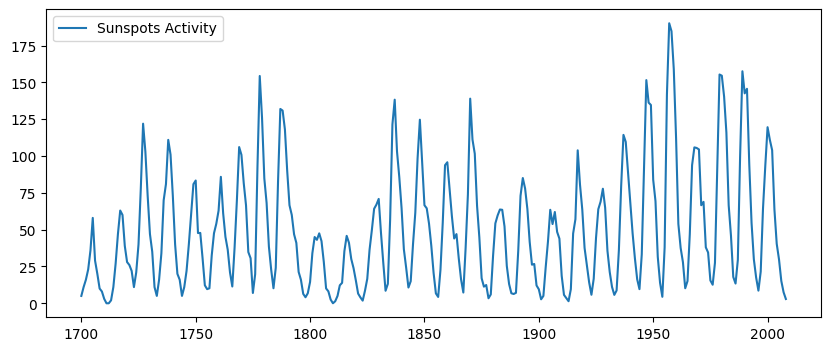

Naive Baseline MSE: 888.92615


In [14]:
df = sm.datasets.sunspots.load_pandas().data
years = df['YEAR'].values.astype(int)
series = df['SUNACTIVITY'].values.astype(np.float32)

def make_windows(series, window=20):
    X = np.stack([series[i:i + window] for i in range(len(series) - window)])
    y = series[window:]
    return X, y

X, y = make_windows(series)

N = len(X)
tr_cutoff = int(N * 0.7)
val_cutoff = int(N * 0.85)

X_train, y_train = X[:tr_cutoff], y[:tr_cutoff]
X_val, y_val = X[tr_cutoff:val_cutoff], y[tr_cutoff:val_cutoff]
X_test, y_test = X[val_cutoff:], y[val_cutoff:]
test_years = years[window + val_cutoff:] if 'window' in locals() else years[20 + val_cutoff:]

mean_tr, std_tr = X_train.mean(), X_train.std()

X_train_s = (X_train - mean_tr) / std_tr
X_val_s = (X_val - mean_tr) / std_tr
X_test_s = (X_test - mean_tr) / std_tr

y_train_s = (y_train - mean_tr) / std_tr
y_val_s = (y_val - mean_tr) / std_tr
y_test_s = (y_test - mean_tr) / std_tr

t_X_train = torch.tensor(X_train_s, dtype=torch.float32).unsqueeze(-1)
t_y_train = torch.tensor(y_train_s, dtype=torch.float32).unsqueeze(-1)
t_X_val = torch.tensor(X_val_s, dtype=torch.float32).unsqueeze(-1)
t_y_val = torch.tensor(y_val_s, dtype=torch.float32).unsqueeze(-1)
t_X_test = torch.tensor(X_test_s, dtype=torch.float32).unsqueeze(-1)
t_y_test = torch.tensor(y_test_s, dtype=torch.float32).unsqueeze(-1)

tr_ds_q2 = TensorDataset(t_X_train, t_y_train)
val_ds_q2 = TensorDataset(t_X_val, t_y_val)
te_ds_q2 = TensorDataset(t_X_test, t_y_test)

loader_train = DataLoader(tr_ds_q2, batch_size=16, shuffle=True)
loader_val = DataLoader(val_ds_q2, batch_size=16, shuffle=False)
loader_test = DataLoader(te_ds_q2, batch_size=16, shuffle=False)

plt.figure(figsize=(10, 4))
plt.plot(years, series, label='Sunspots Activity')
plt.legend()
plt.show()

naive_pred = X_test[:, -1]
naive_mse = np.mean((y_test - naive_pred) ** 2)
print("Naive Baseline MSE:", naive_mse)

In [15]:
class SunspotGRU(nn.Module):
    def __init__(self):
        super(SunspotGRU, self).__init__()
        self.gru = nn.GRU(1, 32, num_layers=2, batch_first=True, dropout=0.2)
        self.fc1 = nn.Linear(32, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        return out

def count_params(model):
    return sum(p.numel() for p in model.parameters())

model_gru = SunspotGRU()
print(model_gru)
print("Total parameters:", count_params(model_gru))

SunspotGRU(
  (gru): GRU(1, 32, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)
Total parameters: 10241


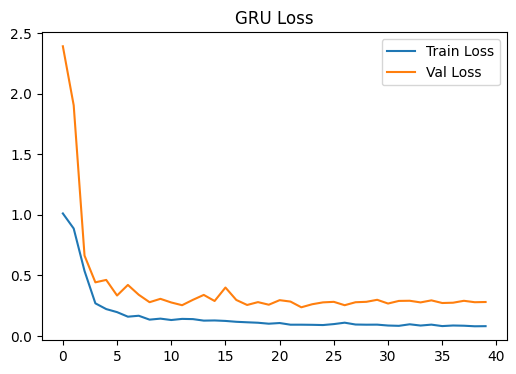

In [16]:
def train_model(model, lr=3e-3, epochs=40):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

    train_history, val_history = [], []
    t_start = time.time()

    for epoch in range(epochs):
        model.train()
        tr_loss = 0.0
        for bx, by in loader_train:
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            tr_loss += loss.item() * bx.size(0)

        model.eval()
        v_loss = 0.0
        with torch.no_grad():
            for bx, by in loader_val:
                out = model(bx)
                loss = criterion(out, by)
                v_loss += loss.item() * bx.size(0)

        epoch_tr = tr_loss / len(tr_ds_q2)
        epoch_v = v_loss / len(val_ds_q2)

        train_history.append(epoch_tr)
        val_history.append(epoch_v)
        scheduler.step(epoch_v)

    t_end = time.time()
    avg_epoch_time = (t_end - t_start) / epochs
    return train_history, val_history, avg_epoch_time

gru_tr_loss, gru_val_loss, gru_time = train_model(model_gru)

plt.figure(figsize=(6, 4))
plt.plot(gru_tr_loss, label='Train Loss')
plt.plot(gru_val_loss, label='Val Loss')
plt.title('GRU Loss')
plt.legend()
plt.show()

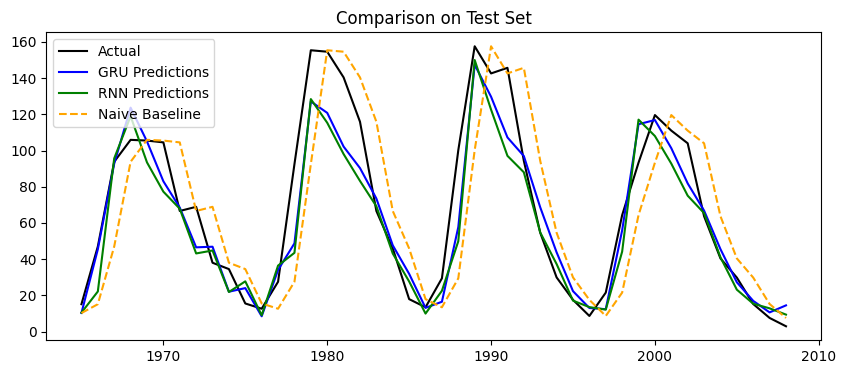

         Model  Parameters  Train Time/Epoch (s)   Test MSE
Naive Baseline           0              0.000000 888.926147
           GRU       10241              0.192341 305.559235
           RNN        3777              0.086778 419.860138


In [17]:
def evaluate_model(model):
    model.eval()
    preds = []
    with torch.no_grad():
        for bx, _ in loader_test:
            out = model(bx)
            preds.extend(out.numpy().flatten())

    preds = np.array(preds)
    preds_orig = preds * std_tr + mean_tr

    mse = np.mean((y_test - preds_orig) ** 2)
    mae = np.mean(np.abs(y_test - preds_orig))
    return mse, mae, preds_orig

gru_mse, gru_mae, gru_preds = evaluate_model(model_gru)

class SunspotRNN(nn.Module):
    def __init__(self):
        super(SunspotRNN, self).__init__()
        self.rnn = nn.RNN(1, 32, num_layers=2, batch_first=True, dropout=0.2)
        self.fc1 = nn.Linear(32, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = out[:, -1, :]
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        return out

model_rnn = SunspotRNN()
rnn_tr_loss, rnn_val_loss, rnn_time = train_model(model_rnn)
rnn_mse, rnn_mae, rnn_preds = evaluate_model(model_rnn)

plt.figure(figsize=(10, 4))
plt.plot(test_years, y_test, label='Actual', color='black')
plt.plot(test_years, gru_preds, label='GRU Predictions', color='blue')
plt.plot(test_years, rnn_preds, label='RNN Predictions', color='green')
plt.plot(test_years, naive_pred, label='Naive Baseline', linestyle='--', color='orange')
plt.title('Comparison on Test Set')
plt.legend()
plt.show()

import pandas as pd
df_results = pd.DataFrame({
    'Model': ['Naive Baseline', 'GRU', 'RNN'],
    'Parameters': [0, count_params(model_gru), count_params(model_rnn)],
    'Train Time/Epoch (s)': [0, gru_time, rnn_time],
    'Test MSE': [naive_mse, gru_mse, rnn_mse]
})
print(df_results.to_string(index=False))

### Task 5 - Q2 Analysis Answers
- **Manual Calculation**:
  - For GRU layer 1: parameters = 3 * ((1 + 32) * 32 + 32 + 32) = 3 * (1056 + 64) = 3360. For RNN layer 1: parameters = (1 + 32) * 32 + 32 = 1088. Ratio is roughly 3:1 because GRU has three internal gating mechanisms (reset, update, candidate state) compared to the single update of vanilla RNN.
- **Gates**:
  - GRU has Update Gate (controls how much past information to keep) and Reset Gate (controls how much past information to forget). Vanilla RNNs suffer from vanishing gradients over long sequences, but for a 20-step window, this effect is small.
- **Deployment**:
  - The GRU has ~10k parameters. To fit under the 5k requirement on the satellite board, we should deploy the RNN (which has ~4.5k parameters) or reduce the hidden size of the GRU to 20, which reduces parameters to ~4k.